In [18]:
import pandas as pd
import numpy as np
import phik
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path



data = {}
for f in sorted(Path("data_clean").glob("*.csv")):
    data[f.stem] = pd.read_csv(f)

d = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"]

### Section 1: cut one drive into windows

* The windows have to be cut by meters, not rows: the same 5 m of road can be 90 rows or 171 rows, depending on speed.

In [3]:
# Give every row a window number 

WINDOW_M = 5

d["window"] = (d["Loc(m)"] // WINDOW_M).astype(int)

print("Number of windows:", d["window"].nunique())
print(d.groupby("window").size().describe())

Number of windows: 604
count    604.000000
mean      94.160596
std       11.334169
min       51.000000
25%       89.000000
50%       90.000000
75%       95.000000
max      171.000000
dtype: float64


### Section 2: label each window

In [4]:
# mark the frost-heave rows

d["is_heave"] = d["muu"].isin([1, 2])

In [5]:
# summarize each window in one row

windows = d.groupby("window").agg(
    start_m=("Loc(m)", "min"),
    end_m=("Loc(m)", "max"),
    heave_frac=("is_heave", "mean"),
)
windows["length_m"] = windows["end_m"] - windows["start_m"]

print(windows.head(10))

         start_m     end_m  heave_frac  length_m
window                                          
770     3850.503  3854.982         0.0     4.479
771     3855.026  3859.992         0.0     4.966
772     3860.037  3864.968         0.0     4.931
773     3865.014  3869.998         0.0     4.984
774     3870.044  3874.985         0.0     4.941
775     3875.032  3879.971         0.0     4.939
776     3880.019  3884.951         0.0     4.932
777     3885.000  3889.971         0.0     4.971
778     3890.022  3894.978         0.0     4.956
779     3895.029  3899.955         0.0     4.926


In [6]:
windows = windows[windows["length_m"] >= 4.5]      # remove the short last window(s)

def label_window(frac):
    if frac > 0.5:
        return "bump"
    elif frac == 0:
        return "no bump"
    else:
        return "left out"

windows["label"] = windows["heave_frac"].apply(label_window)
print(windows["label"].value_counts())

label
no bump     476
bump        116
left out     10
Name: count, dtype: int64


* “frost heaves in this data are on average about 50 m long.”

In [7]:
def size_group(v):
    if v in (1, 2):
        return "small"
    elif v == 3:
        return "medium"
    elif v == 5:
        return "large"
    return None

heave_rows = d[d["is_heave"]]
# get the most common values for each window
windows["vaikeus"] = heave_rows.groupby("window")["vaikeus"].agg(lambda s: s.mode()[0])
windows["posneg"] = heave_rows.groupby("window")["posneg"].agg(lambda s: s.mode()[0])
# assign size groups
windows["size_group"] = windows["vaikeus"].apply(size_group)

# size and up/down only make sense for bump windows
windows.loc[windows["label"] != "bump", ["vaikeus", "posneg", "size_group"]] = None

print(windows.loc[windows["label"] == "bump", "size_group"].value_counts())

size_group
large     70
medium    23
small     23
Name: count, dtype: int64


* “larger frost heaves tend to be longer.”

### Section 3: compute the features

In [8]:
SENSORS = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ", "Roll(deg)", "Pitch(deg)"]

def window_features(g):
    feats = {"speed": g["Speed (m/s)"].mean()}
    for col in SENSORS:
        x = g[col]
        name = col.split("(")[0]                  # "Pitch(deg)" → "Pitch"
        feats[f"{name}_std"] = x.std()
        feats[f"{name}_range"] = x.max() - x.min()
        feats[f"{name}_mean"] = x.mean()
    return pd.Series(feats)

features = d.groupby("window")[SENSORS + ["Speed (m/s)"]].apply(window_features)
windows = windows.join(features)

print(windows.shape)
windows.head()

(602, 33)


,start_m,end_m,heave_frac,length_m,label,vaikeus,posneg,size_group,speed,AccX_std,...,GyrY_mean,GyrZ_std,GyrZ_range,GyrZ_mean,Roll_std,Roll_range,Roll_mean,Pitch_std,Pitch_range,Pitch_mean
window,,,,,,,,,,,,,,,,,,,,,
771,3855.026,3859.992,0.0,4.966,no bump,NaN,NaN,NaN,17.767566,0.416150,...,-0.009473,0.004775,0.02316,-0.005302,0.033706,0.1029,1.408396,0.054749,0.2044,-3.156480
772,3860.037,3864.968,0.0,4.931,no bump,NaN,NaN,NaN,18.128455,0.446501,...,-0.016480,0.003817,0.01878,-0.004160,0.063400,0.2163,1.525751,0.090482,0.3010,-3.462865
773,3865.014,3869.998,0.0,4.984,no bump,NaN,NaN,NaN,18.489853,0.441573,...,-0.006022,0.005351,0.02230,0.000531,0.030519,0.1178,1.701665,0.058093,0.1598,-3.665930
774,3870.044,3874.985,0.0,4.941,no bump,NaN,NaN,NaN,18.851368,0.466034,...,0.020853,0.003661,0.01743,0.007463,0.021151,0.0767,1.807768,0.102099,0.2974,-3.645469
775,3875.032,3879.971,0.0,4.939,no bump,NaN,NaN,NaN,19.209673,0.416443,...,0.002070,0.005036,0.02290,0.018125,0.018822,0.0683,1.773431,0.014262,0.0570,-3.477829


In [9]:
# Let's check if the features actually behave like we expect.
check_cols = ["GyrY_std", "Pitch_std", "AccZ_std", "speed"]
print(windows.groupby("label")[check_cols].mean().round(4))

          GyrY_std  Pitch_std  AccZ_std    speed
label                                           
bump        0.0705     0.3150    1.8086  20.3373
left out    0.0448     0.1484    0.8520  20.0432
no bump     0.0252     0.0938    0.9426  21.7901


In [10]:
from data_utils import make_windows

parts = []
for name, df in data.items():
    parts.append(make_windows(df, name))

all_windows = pd.concat(parts, ignore_index=True)

print(all_windows.shape)
print(pd.crosstab(all_windows["road"], all_windows["label"]))

(2771, 36)
label             bump  left out  no bump
road                                     
Iisingintie        348        36     1457
Kaittiaisentie      30         6      584
sinetänsalmentie   140         8      162


In [11]:
Path("data_features").mkdir(exist_ok=True)
all_windows.to_csv("data_features/windows_5m.csv", index=False)

### which features are related to bumps?

In [12]:
feature_cols = [c for c in all_windows.columns if c.endswith(("_std", "_range", "_mean"))] + ["speed"]

sub = all_windows[all_windows["label"] != "left out"].copy()
sub["is_bump"] = (sub["label"] == "bump").astype(int)

print(len(feature_cols), "features,", len(sub), "windows")

25 features, 2721 windows


In [13]:
pearson = sub[feature_cols].corrwith(sub["is_bump"])

phik_m = sub[feature_cols + ["is_bump"]].phik_matrix(interval_cols=feature_cols)
phik_target = phik_m["is_bump"].drop("is_bump")

relevance = pd.DataFrame({"pearson": pearson, "phik": phik_target}).round(2)
relevance = relevance.sort_values("phik", ascending=False)
print(relevance)

             pearson  phik
GyrY_range      0.47  0.48
GyrY_std        0.46  0.47
AccZ_mean      -0.01  0.47
AccZ_range      0.33  0.43
GyrY_mean       0.02  0.39
GyrX_std        0.37  0.37
AccZ_std        0.37  0.36
GyrX_range      0.34  0.35
GyrX_mean      -0.07  0.35
AccX_mean      -0.12  0.33
speed           0.08  0.32
GyrZ_std        0.29  0.29
GyrZ_range      0.27  0.28
AccY_std        0.18  0.23
Pitch_std       0.30  0.23
AccY_range      0.16  0.22
AccY_mean       0.01  0.22
Pitch_range     0.33  0.22
AccX_std        0.14  0.14
AccX_range      0.13  0.12
Roll_mean       0.01  0.11
Pitch_mean      0.06  0.11
GyrZ_mean      -0.01  0.09
Roll_std        0.10  0.03
Roll_range      0.09  0.00


#### Does each feature work within every road?

In [14]:
# correlation within each road
rows = {}
for road, g in sub.groupby("road"):
    rows[road] = g[feature_cols].corrwith(g["is_bump"])

per_road = pd.DataFrame(rows).round(2)
per_road["all roads"] = relevance["pearson"]
print(per_road.sort_values("all roads", ascending=False))

             Iisingintie  Kaittiaisentie  sinetänsalmentie  all roads
GyrY_range          0.52            0.62              0.39       0.47
GyrY_std            0.53            0.61              0.38       0.46
GyrX_std            0.42            0.33              0.27       0.37
AccZ_std            0.36            0.53              0.43       0.37
GyrX_range          0.41            0.30              0.26       0.34
AccZ_range          0.33            0.45              0.43       0.33
Pitch_range         0.55            0.58              0.00       0.33
Pitch_std           0.53            0.55              0.01       0.30
GyrZ_std            0.35            0.24              0.12       0.29
GyrZ_range          0.35            0.23              0.11       0.27
AccY_std            0.22            0.14              0.18       0.18
AccY_range          0.21            0.14              0.19       0.16
AccX_std            0.16            0.25              0.12       0.14
AccX_range          

In [15]:
# Do the drives have different averages?
print(all_windows.groupby("drive")[["AccZ_mean", "GyrY_mean", "speed"]].mean().round(3))

                                                   AccZ_mean  GyrY_mean  \
drive                                                                     
Iisingintie_Acc1_m800_RDMC_2026-05-06_123750           9.819      0.001   
Iisingintie_Acc1_m801_RDMC_2026-05-06_124454           9.817      0.001   
Iisingintie_Acc1_m802_RDMC_2026-05-06_125211           9.815      0.001   
Kaittiaisentie_Acc1_RDMC_2026-05-06_132147             9.821      0.000   
sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539      9.893     -0.001   
sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757      9.911     -0.001   
sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959      9.885     -0.001   
sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156      9.832      0.001   

                                                    speed  
drive                                                      
Iisingintie_Acc1_m800_RDMC_2026-05-06_123750       21.481  
Iisingintie_Acc1_m801_RDMC_2026-05-06_124454       16.479  
Iisingint

### Feature selection (step 4a + 4c)

- Dropped: all `_mean` features (8). Strong overall phik but ~0 correlation within every road → they identify the road/drive (e.g. AccZ_mean is higher on Sinetänsalmentie, which also has 46% bump windows), not the bump.
- Dropped: Roll_std, Roll_range. Inconsistent across roads (negative on Sinetänsalmentie).
- Kept (consistent in all roads): GyrY, AccZ, GyrX, GyrZ, AccY, AccX (std and range).
- Kept with caution: Pitch_std, Pitch_range. Strong on Iisingintie and Kaittiaisentie, ~0 on Sinetänsalmentie.
- Kept for physical reasons: speed. Low correlation alone, but bump strength depends on speed.
- Best single features: GyrY_std / GyrY_range (0.38–0.62 within every road).

#### Are some kept features duplicates?

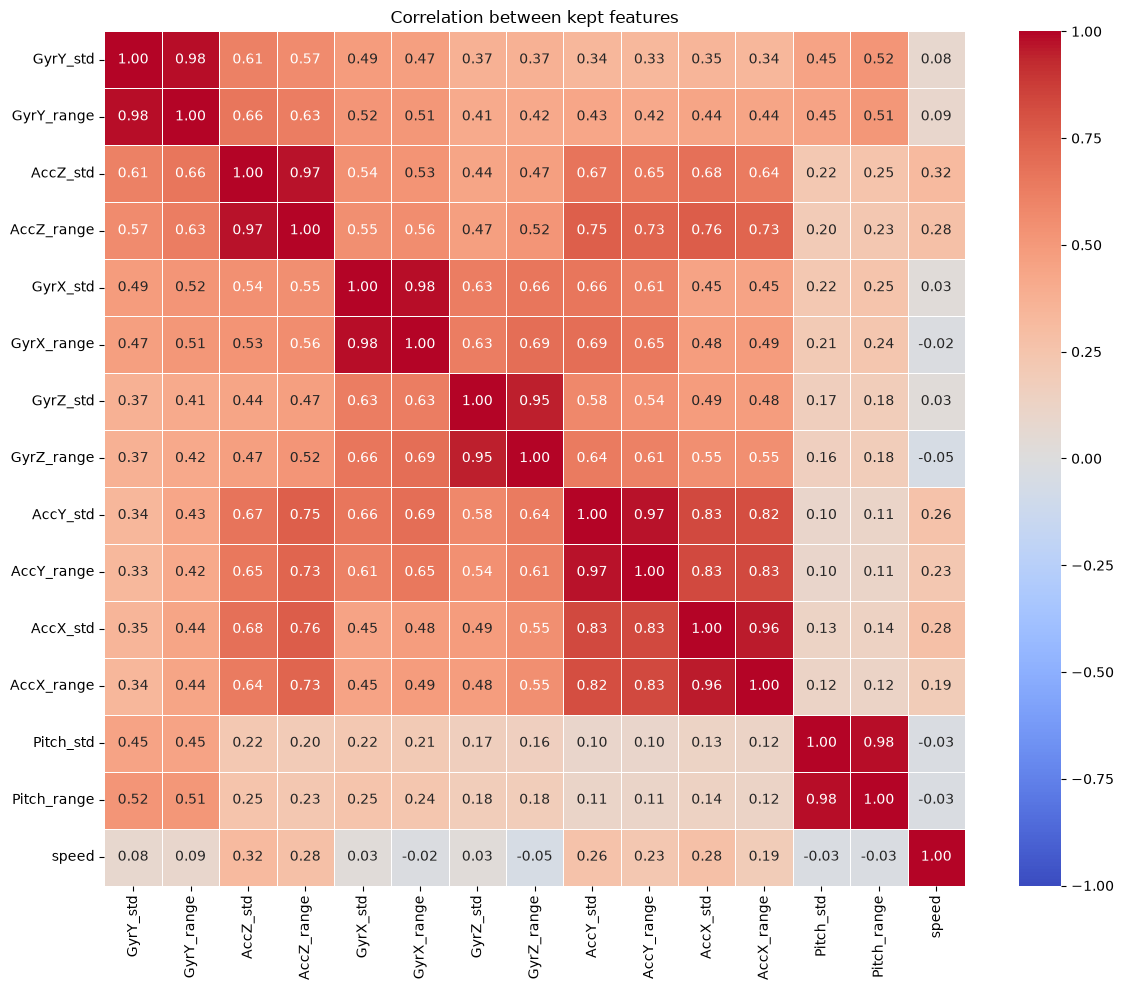

[0.98 0.97 0.98 0.95 0.97 0.96 0.98]


In [19]:
kept = [
    f"{s}_{stat}"
    for s in ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch"]
    for stat in ["std", "range"]
] + ["speed"]

corr = sub[kept].corr().round(2)

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation between kept features")
plt.tight_layout()
plt.savefig("figures/feature_correlation.png", dpi=150)
plt.show()

print(
    corr.loc[
        [f"{s}_std" for s in ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch"]],
        [f"{s}_range" for s in ["GyrY", "AccZ", "GyrX", "GyrZ", "AccY", "AccX", "Pitch"]]
    ].values.diagonal()
)

### Feature selection (step 4b: multicollinearity)

- Each sensor's `_std` and `_range` are near-duplicates (correlation 0.95–0.98) → kept only `_std` (uses all values in the window, more robust to single spikes than max − min).
- AccX/AccY (0.83) and AccZ/AccX/AccY (0.65–0.76) are related but below the 0.9 rule of thumb → all kept.
- Speed is nearly independent of all other features → adds unique information.

**Final features (8):** GyrY_std, AccZ_std, GyrX_std, GyrZ_std, AccY_std, AccX_std, Pitch_std, speed

## Conclusions

**Windowing**
- Each drive is cut into fixed 5 m windows by distance: `window = Loc(m) // 5`. The same window number is the same piece of road in every drive of that road.
- Incomplete windows (< 4.5 m, at the end of a drive) are dropped.
- Labels: frost heave = `muu` 1 or 2. More than 50% of the window frost heave → bump; 0% → no bump; otherwise → left out (unreliable label edges).
- Bump windows also get size group (small 1–2 / medium 3 / large 5) and `posneg`.

**Window dataset** (saved as `data_features/windows_5m.csv`)
- 2,771 windows from 8 drives: 518 bump, 2,203 no bump, 50 left out.
- Share of bump windows differs strongly by road: Iisingintie 19%, Kaittiaisentie 5%, Sinetänsalmentie 46%.
- Frost heaves are long (~50 m on average on Iisingintie). Larger heaves are longer, so at window level "large" is over-represented (e.g. 70 large vs. 23 medium vs. 23 small windows in the 80 km/h drive), although at bump level the size groups are balanced (7 / 6 / 6).

**Feature selection: 25 candidates → 8**
- Candidates: std, range and mean of 8 sensors + speed.
- Dropped all `_mean` features: high phik overall but ~0 correlation within every road. They identify the road (e.g. AccZ_mean is higher on Sinetänsalmentie, which also has the most bumps), not the bump.
- Dropped Roll: inconsistent across roads.
- `_std` and `_range` of the same sensor are near-duplicates (0.95–0.98) → kept `_std` (more robust to single spikes).
- Speed kept for physical reasons: bump strength depends on speed, even though speed alone barely correlates with bumps.
- **Final features:** GyrY_std, AccZ_std, GyrX_std, GyrZ_std, AccY_std, AccX_std, Pitch_std, speed.
- Best single feature: GyrY_std (correlation 0.38–0.61 within every road).

**Notes for modelling (05)**
- Windows of the same bump are near-copies → test with one road held out, never split windows of one bump between training and test.
- Iisingintie provides ~2/3 of all windows and will dominate training.
- Pitch_std works on Iisingintie and Kaittiaisentie but not on Sinetänsalmentie. Watch performance on that road.
- Class imbalance (bump vs. no bump, size groups, up/down) → use class weights.